# 09 · Hipótese do formato em V

Na primeira rodada do experimento, alguns dos planetas perdidos pela CNN tinham trânsitos muito profundos e SNR muito alto, como o Kepler-428 b (K00830.01, 22.335 ppm, SNR 1.996,7), que deveriam ser casos fáceis. Este notebook testa uma explicação: como a normalização remove a profundidade absoluta, o modelo vê apenas o formato do trânsito, e um trânsito profundo e rasante tende ao formato em V, típico das binárias eclipsantes da classe negativa.

O teste compara o formato da Visão Local em três grupos: planetas perdidos pela CNN, planetas classificados corretamente e falsos positivos.

A versão publicada foi executada sobre os dados da rodada final (`views_v2/`). A hipótese não se sustentou, e a causa real dos erros da primeira rodada era o artefato do corte de *outliers*, analisado no notebook 10 (Apêndice B do TCC, Seções B.3 e B.4).

Requer o `predicoes_teste.csv` do notebook 06. Não precisa de GPU.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/TCC-Exoplanetas'
VIEWS_DIR = f'{DATA_DIR}/views_v2'
FIG_DIR   = f'{DATA_DIR}/figuras'
os.makedirs(FIG_DIR, exist_ok=True)

pred = pd.read_csv(f'{DATA_DIR}/predicoes_teste.csv')
print('predicoes:', pred.shape)
pred.head(3)

Mounted at /content/drive
predicoes: (670, 13)


,kepoi_name,y,prob_cnn1d,acerto_cnn1d,prob_bilstm,acerto_bilstm,prob_transformer,acerto_transformer,koi_depth,koi_model_snr,koi_period,koi_prad,kepler_name
0,K00028.01,0,0.000006,True,0.000477,True,0.000010,True,123521.0,2619.2,4.100870,82.46,NaN
1,K00044.01,0,0.614454,False,0.559037,False,0.966343,False,12643.7,1049.3,66.467462,11.97,NaN
2,K00045.01,0,0.003599,True,0.021212,True,0.001984,True,18887.0,394.7,6.397186,15.02,NaN


In [ ]:
def carregar_visoes(kepoi):
    z = np.load(f'{VIEWS_DIR}/{kepoi}.npz')
    return z['global_view'], z['local_view']

# planetas confirmados que a CNN errou, ordenados por profundidade (os mais "faceis")
fn_cnn = pred[(pred.y == 1) & (~pred.acerto_cnn1d)].sort_values('koi_depth', ascending=False)
print(f'Falsos negativos da CNN: {len(fn_cnn)}')
cols = ['kepoi_name', 'kepler_name', 'koi_depth', 'koi_model_snr', 'koi_prad', 'prob_cnn1d']
display(fn_cnn.head(8)[cols])

Falsos negativos da CNN: 18


,kepoi_name,kepler_name,koi_depth,koi_model_snr,koi_prad,prob_cnn1d
400,K03728.01,Kepler-1517 b,2211.0,56.4,22.27,0.415441
46,K00408.01,Kepler-150 c,1433.8,101.6,3.42,0.385528
183,K01581.01,Kepler-896 c,879.9,39.5,3.15,0.079601
430,K04036.01,Kepler-1544 b,614.4,15.3,1.69,0.070251
232,K01989.01,Kepler-1040 b,584.8,34.7,2.28,0.005957
155,K01241.01,Kepler-56 c,409.3,60.9,11.64,0.496893
255,K02133.01,Kepler-91 b,396.8,63.6,14.93,0.060183
313,K02851.01,Kepler-1985 b,356.8,13.9,2.27,0.323148


## 1. Curvas dos planetas perdidos

Visão Local (formato do trânsito) e Visão Global (presença de eclipse secundário) dos planetas mais profundos que a CNN classificou como falso positivo.

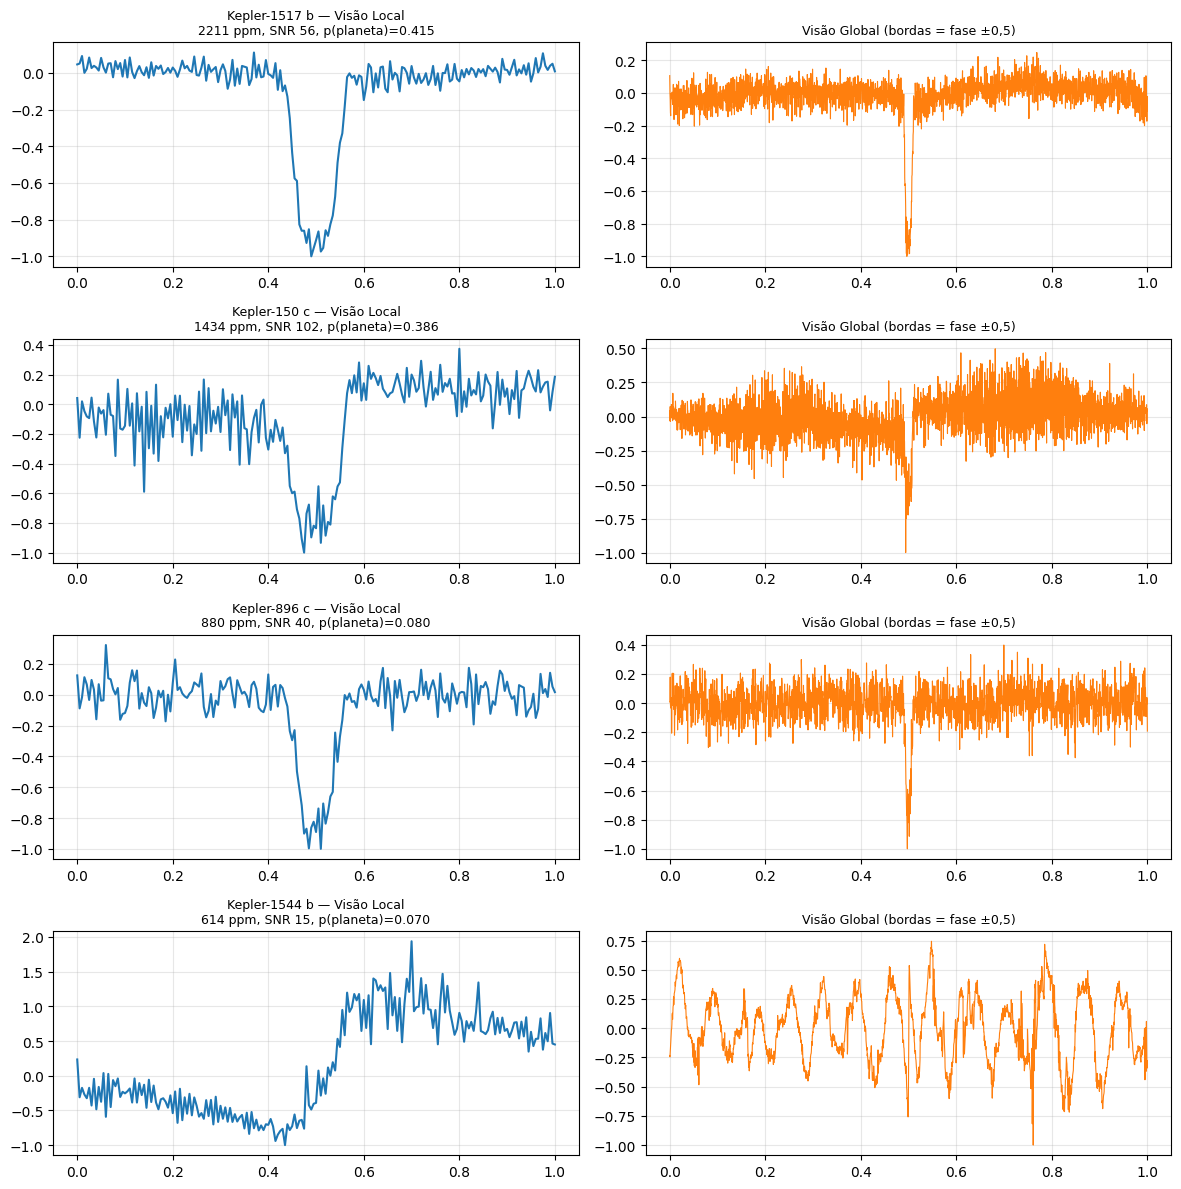

In [ ]:
casos = fn_cnn.head(4)
fig, axes = plt.subplots(len(casos), 2, figsize=(12, 3 * len(casos)))

for eixo, (_, r) in zip(axes, casos.iterrows()):
    g, l = carregar_visoes(r.kepoi_name)
    nome = r.kepler_name if isinstance(r.kepler_name, str) else r.kepoi_name
    eixo[0].plot(np.linspace(0, 1, len(l)), l, color='C0')
    eixo[0].set_title(f'{nome} — Visão Local\n{r.koi_depth:.0f} ppm, SNR {r.koi_model_snr:.0f}, '
                      f'p(planeta)={r.prob_cnn1d:.3f}', fontsize=9)
    eixo[1].plot(np.linspace(0, 1, len(g)), g, color='C1', lw=0.8)
    eixo[1].set_title('Visão Global (bordas = fase ±0,5)', fontsize=9)
    for a in eixo: a.grid(alpha=0.3)

plt.tight_layout(); plt.savefig(f'{FIG_DIR}/erros_profundos_curvas.png', dpi=300); plt.show()

## 2. Índice de formato

Num trânsito planetário típico, o fundo é achatado (formato em U); num eclipse rasante de binária, é pontiagudo (formato em V). O índice é a razão entre a profundidade média em um centro estreito (5% da janela) e em um centro largo (25% da janela):

- fundo achatado: as duas profundidades são parecidas, e o índice fica perto de 1;
- fundo pontiagudo: o centro é bem mais fundo, e o índice fica bem acima de 1.

É uma medida simples, que ordena os casos pelo formato sem substituir o ajuste de um modelo de trânsito.

In [ ]:
def indice_v(l):
    """~1 = fundo achatado (U); >1 = fundo pontiagudo (V)."""
    n = len(l)
    c = n // 2
    estreito = l[c - max(1, n // 40): c + max(1, n // 40)]     # ~5% da janela
    largo    = l[c - max(1, n // 8):  c + max(1, n // 8)]      # ~25% da janela
    p_estreito, p_largo = -estreito.mean(), -largo.mean()
    return p_estreito / p_largo if p_largo > 0 else np.nan

indices = []
for kepoi in pred.kepoi_name:
    try:
        _, l = carregar_visoes(kepoi)
        indices.append(indice_v(l))
    except Exception:
        indices.append(np.nan)
pred['indice_v'] = indices
print('indice V calculado para', pred.indice_v.notna().sum(), 'KOIs do teste')

indice V calculado para 659 KOIs do teste


,Grupo,n,indice V (mediana),indice V (media),profundidade mediana (ppm)
0,Planetas errados pela CNN,18,2.515,2.546,244.9
1,Planetas acertados,233,2.430,3.247,484.5
2,Falsos positivos (reais),408,2.849,2.830,1107.7


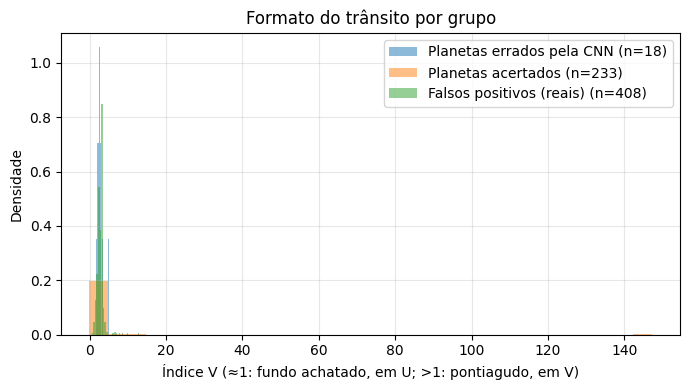

In [ ]:
# Tres grupos de comparacao
grupos = {
    'Planetas errados pela CNN':  pred[(pred.y == 1) & (~pred.acerto_cnn1d)],
    'Planetas acertados':          pred[(pred.y == 1) & (pred.acerto_cnn1d)],
    'Falsos positivos (reais)':    pred[pred.y == 0],
}

linhas = []
for nome, g in grupos.items():
    v = g.indice_v.dropna()
    linhas.append({'Grupo': nome, 'n': len(v),
                   'indice V (mediana)': round(v.median(), 3),
                   'indice V (media)': round(v.mean(), 3),
                   'profundidade mediana (ppm)': round(g.koi_depth.median(), 1)})
display(pd.DataFrame(linhas))

plt.figure(figsize=(7, 4))
for nome, g in grupos.items():
    v = g.indice_v.dropna()
    plt.hist(v, bins=30, alpha=0.5, density=True, label=f'{nome} (n={len(v)})')
plt.xlabel('Índice V (≈1: fundo achatado, em U; >1: pontiagudo, em V)')
plt.ylabel('Densidade'); plt.legend(); plt.grid(alpha=0.3)
plt.title('Formato do trânsito por grupo')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/indice_v_grupos.png', dpi=300); plt.show()

## 3. Resultado do teste

Compara os grupos pela mediana, pelo intervalo interquartil e pelo d de Cohen. A diferença só é considerada relevante se for grande em relação à dispersão dentro dos grupos.

In [ ]:
v_err = grupos['Planetas errados pela CNN'].indice_v.dropna()
v_ok  = grupos['Planetas acertados'].indice_v.dropna()
v_fp  = grupos['Falsos positivos (reais)'].indice_v.dropna()

print('indice V — mediana [intervalo interquartil]:')
for v, nome in [(v_err, 'planetas errados'), (v_ok, 'planetas acertados'), (v_fp, 'falsos positivos')]:
    q1, q3 = v.quantile(0.25), v.quantile(0.75)
    print(f'  {nome:20s} {v.median():.3f}  [{q1:.3f} – {q3:.3f}]   n={len(v)}')

# Tamanho de efeito (d de Cohen com desvio combinado), robusto a diferencas triviais.
def cohen_d(a, b):
    na, nb = len(a), len(b)
    s = np.sqrt(((na - 1) * a.std(ddof=1) ** 2 + (nb - 1) * b.std(ddof=1) ** 2) / (na + nb - 2))
    return (a.mean() - b.mean()) / s if s > 0 else np.nan

d_ok = cohen_d(v_err, v_ok)
dif_mediana = v_err.median() - v_ok.median()
amplitude = v_ok.quantile(0.75) - v_ok.quantile(0.25)   # escala tipica do indice

print(f'\nErrados vs acertados:')
print(f'  diferenca das medianas: {dif_mediana:+.3f}')
print(f'  amplitude interquartil dos acertados (escala de referencia): {amplitude:.3f}')
print(f'  razao diferenca/escala: {abs(dif_mediana)/amplitude:.2f}')
print(f'  d de Cohen: {d_ok:.2f}')

# Criterio: a diferenca precisa ser relevante FRENTE A DISPERSAO, nao apenas positiva.
relevante = abs(dif_mediana) > 0.5 * amplitude and abs(d_ok) > 0.3

print('\n' + '=' * 70)
if not relevante:
    print('HIPOTESE NAO SUSTENTADA.')
    print('A diferenca de formato entre os grupos e pequena frente a dispersao interna —')
    print('as distribuicoes se sobrepoem. O indice V nao distingue os planetas errados dos')
    print('acertados, logo o formato em V NAO explica os erros.')
    print('Conferir tambem as curvas da Secao 1: se mostrarem fundo achatado (caixa/U),')
    print('isso confirma visualmente a refutacao.')
    print('\nCausas alternativas a investigar: saturacao em alvos muito brilhantes,')
    print('variabilidade estelar, distorcao do flattening em transitos profundos, ou')
    print('associacao entre profundidade e a classe negativa por outro mecanismo.')
else:
    print('HIPOTESE COMPATIVEL COM OS DADOS (efeito relevante frente a dispersao).')
    print('Confirmar visualmente nas curvas da Secao 1 antes de afirmar no texto.')
print('=' * 70)
print('\nATENCAO: medias podem enganar aqui. Se media >> mediana, ha poucos valores')
print('extremos na cauda inflando a media — nao e padrao sistematico.')
print(f'  errados: media {v_err.mean():.3f} vs mediana {v_err.median():.3f}')

indice V — mediana [intervalo interquartil]:
  planetas errados     2.515  [2.279 – 2.869]   n=18
  planetas acertados   2.430  [2.284 – 2.655]   n=233
  falsos positivos     2.849  [2.328 – 3.229]   n=408

Errados vs acertados:
  diferenca das medianas: +0.084
  amplitude interquartil dos acertados (escala de referencia): 0.371
  razao diferenca/escala: 0.23
  d de Cohen: -0.08

HIPOTESE NAO SUSTENTADA.
A diferenca de formato entre os grupos e pequena frente a dispersao interna —
as distribuicoes se sobrepoem. O indice V nao distingue os planetas errados dos
acertados, logo o formato em V NAO explica os erros.
Conferir tambem as curvas da Secao 1: se mostrarem fundo achatado (caixa/U),
isso confirma visualmente a refutacao.

Causas alternativas a investigar: saturacao em alvos muito brilhantes,
variabilidade estelar, distorcao do flattening em transitos profundos, ou
associacao entre profundidade e a classe negativa por outro mecanismo.

ATENCAO: medias podem enganar aqui. Se media >>

## 4. Formato médio por grupo

Visão Local média dos três grupos.

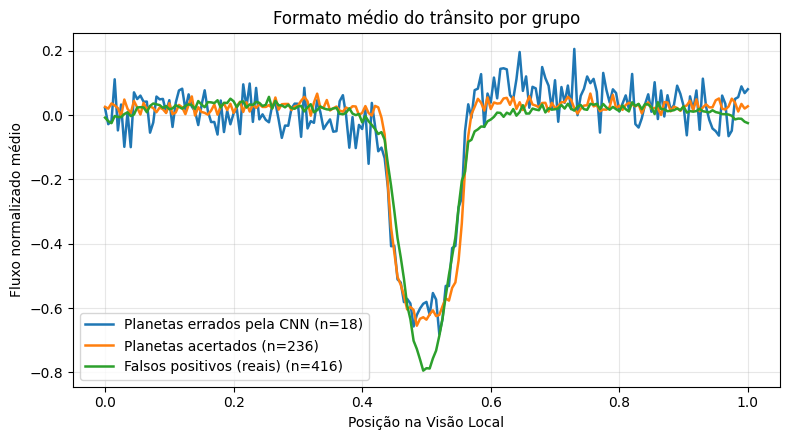

In [ ]:
def media_visao_local(g):
    curvas = []
    for kepoi in g.kepoi_name:
        try:
            _, l = carregar_visoes(kepoi)
            curvas.append(l)
        except Exception:
            pass
    return np.mean(curvas, axis=0) if curvas else None

plt.figure(figsize=(8, 4.5))
for nome, g in grupos.items():
    m = media_visao_local(g)
    if m is not None:
        plt.plot(np.linspace(0, 1, len(m)), m, lw=1.8, label=f'{nome} (n={len(g)})')
plt.xlabel('Posição na Visão Local'); plt.ylabel('Fluxo normalizado médio')
plt.title('Formato médio do trânsito por grupo')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/formato_medio_grupos.png', dpi=300); plt.show()

## Conclusão

Na rodada final, os planetas perdidos e os classificados corretamente tiveram índices praticamente iguais (medianas de 2,52 e 2,43; d de Cohen = −0,08), e a hipótese não se sustentou. Além disso, os planetas perdidos na rodada final não são profundos: a profundidade mediana deles é de 245 ppm. Os erros em trânsitos profundos da primeira rodada vinham do corte de *outliers* simétrico, que apagava o fundo desses trânsitos (notebook 10).

Limitações: o índice é uma medida simples de formato, o grupo de planetas perdidos é pequeno (18) e a análise usa só o modelo da semente 42.